# Verarbeitung und Darstellung der Messdaten



## Import all libraries and load data as pandas dataframe


In [2]:
#import libraries
import pandas as pd
import numpy as np
import scipy.signal as sci
import matplotlib.pyplot as plot

In [13]:

#import recorded .csv Files and store them in a dataframe
df = pd.read_csv(
    "ACC_Data_Aufgabe1.5_4g.100.txt",
    sep=r"\s+",
    header=None,
    names=["Time", "X", "Y", "Z"]
)

#convert time from ms into s
df['Time'] = df['Time'].div(1000)
df['X'] = df['X'].div(500)
df['Y'] = df['Y'].div(500)
df['Z'] = df['Z'].div(500)


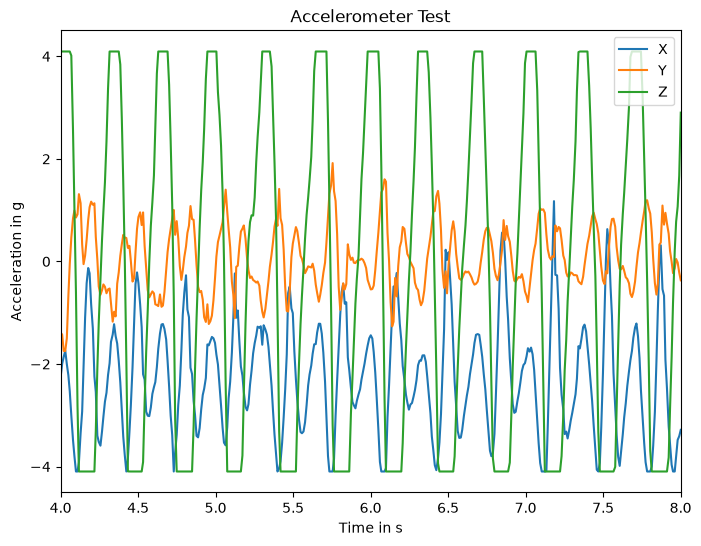

: 

In [ ]:
# display data
df.plot(x = 'Time', y = ['X', 'Y', 'Z'], ylabel='Acceleration in g', 
        xlabel='Time in s', figsize= [8, 6], title="Accelerometer Test", xlim=(4,8))
plot.savefig("Plot_1_4_2g_12.png", bbox_inches="tight")

# Filter acceleration data applying different filter techniques
## Bandpass filter (Butterworth 4. order)

Wir möchten einen Filter verwende, der das Signal nicht verschiebt, demnach einen zero-Phase Filter. Scipy bietet diese Option mit der _filtfilt()_ Methode an. Dieser verwendet zwei _Infinite Impuls Response_ Filter hintereinander geschaltet, jedoch wird der erste vorwärts und der zweite rückwärts angewandt, um keine Phasenverschiebung zu erhalten.

Dies ist auch in folgender Abbildung zu erkennen. Die gestrichelte rote Line stellt einen Filter dar, welcher das Signal filtert und störende Frequenzen entfernt, jedoch ist dieser um eine Phase verschoben zum eigentlichen Signal. Die rote Line ist die zweite Anwendung des Filters. Würde man den zweiten Filter jedoch rückwärts anwenden, würde man die schwarze Linie und somit das Ergebnis der _filtfilt()_ methode erhalten.



![Unterschied zwischen verschiedenen Filtertypen](bilder/zeroPhase.png)

Abtastfrequenz: 12.66 Hz


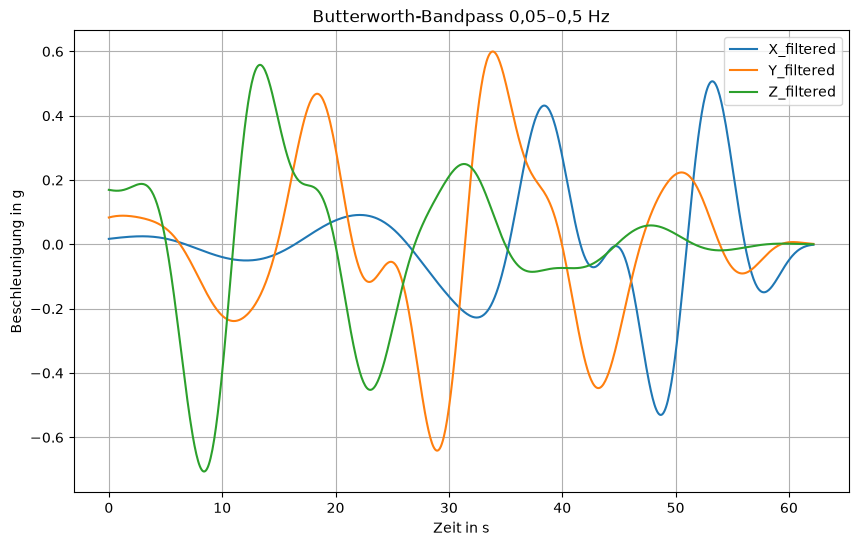

In [76]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal as sci


# Messdaten einlesen
df = pd.read_csv(
    "ACC_Data_Aufgabe1.6_2g.12.txt",
    sep=r"\s+",
    header=None,
    names=["Time_ms", "X", "Y", "Z"]
)

# Zeit in Sekunden, beginnend bei 0 s
df["Time"] = (
    df["Time_ms"] - df["Time_ms"].iloc[0]
) / 1000

# Beschleunigung von mg in g umrechnen
axes = ["X", "Y", "Z"]
df[axes] = df[axes] / 1000


# Abtastfrequenz aus den Zeitstempeln berechnen
dt = np.median(np.diff(df["Time"]))
fs = 1 / dt

print(f"Abtastfrequenz: {fs:.2f} Hz")


def butter_bandpass(lowcut, highcut, fs, order=4):
    nyquist = fs / 2

    if lowcut <= 0:
        raise ValueError("lowcut muss größer als 0 Hz sein.")

    if highcut >= nyquist:
        raise ValueError(
            f"highcut muss kleiner als {nyquist:.2f} Hz sein."
        )

    if lowcut >= highcut:
        raise ValueError("lowcut muss kleiner als highcut sein.")

    # Beim Bandpass werden zwei Grenzfrequenzen benötigt
    b, a = sci.butter(
        order,
        [lowcut, highcut],
        btype="bandpass",
        fs=fs
    )

    return b, a


def butter_bandpass_filter(
    data,
    lowcut,
    highcut,
    fs,
    order=4
):
    b, a = butter_bandpass(
        lowcut,
        highcut,
        fs,
        order
    )

    # Vorwärts und rückwärts filtern:
    # keine zeitliche Phasenverschiebung
    filtered_data = sci.filtfilt(
        b,
        a,
        data,
        axis=0
    )

    return filtered_data


# Filterparameter
lowcut = 0.05   # Untere Grenzfrequenz in Hz
highcut = 0.15   # Obere Grenzfrequenz in Hz
order = 4

filtered_data = butter_bandpass_filter(
    df[axes].to_numpy(),
    lowcut,
    highcut,
    fs,
    order
)

df[["X_filtered", "Y_filtered", "Z_filtered"]] = filtered_data

df.plot(
    x="Time",
    y=["X_filtered", "Y_filtered", "Z_filtered"],
    xlabel="Zeit in s",
    ylabel="Beschleunigung in g",
    title="Butterworth-Bandpass 0,05–0,5 Hz",
    figsize=(10, 6),
    grid=True
)

plt.show()

In [46]:
# Setting up a butterworth filter 

def butter_bandpass(lowcut,fs,order):
    
    # nyq: Nyquist Theorem
    nyq = 0.5 * fs
    # low is calculated in relation to cutoff frequency and sampling frequency
    low = lowcut / nyq
    
    order = 4
    
    b, a = sci.butter(order, [low], 'lowpass', analog=False)
    
    return b, a


In [48]:
def butter_bandpass_filter(signal, lowcut, fs, order):
    #use filtfilt for a zero-phase filtering
    b, a = butter_bandpass(lowcut,fs, order)
    y = sci.filtfilt(b, a, signal, axis = 0, order = 4)
    return y

In [49]:
lowcut = 0.5
fs =12
order = 4
df = pd.read_csv(
    "ACC_Data_Aufgabe1.6_2g.12.txt",
    sep=r"\s+",
    header=None,
    names=["X", "Y", "Z", "Time"]
)
signal_neu = butter_bandpass_filter(df[["X", "Y", "Z"]], lowcut, fs, order)

TypeError: only 0-dimensional arrays can be converted to Python scalars

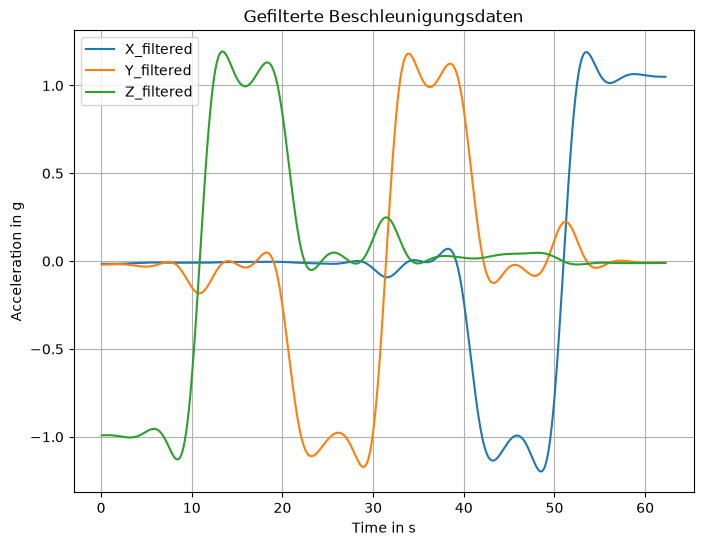

In [84]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal as sci


df = pd.read_csv(
    "ACC_Data_Aufgabe1.6_2g.12.txt",
    sep=r"\s+",
    header=None,
    names=["Time", "X", "Y", "Z",]
)

# Sicherstellen, dass alle Werte numerisch sind
columns = ["Time", "X", "Y", "Z"]
df[columns] = df[columns].apply(pd.to_numeric, errors="coerce")
df = df.dropna(subset=columns)

# Millisekunden in Sekunden umrechnen
df["Time"] = df["Time"] / 1000
df[["X", "Y", "Z"]] = df[["X", "Y", "Z"]] / 1000


def butter_lowpass_filter(data, cutoff, fs, order=4):
    cutoff = float(cutoff)
    fs = float(fs)
    order = int(order)

    # Numerisch stabile SOS-Filterdarstellung
    sos = sci.butter(
        order,
        cutoff,
        btype="lowpass",
        fs=fs,
        output="sos"
    )

    return sci.sosfiltfilt(
        sos,
        np.asarray(data, dtype=float),
        axis=0
    )


cutoff = 0.2  
fs = 12.66
order = 4

df[["X_filtered", "Y_filtered", "Z_filtered"]] = (
    butter_lowpass_filter(
        df[["X", "Y", "Z"]],
        cutoff,
        fs,
        order
    )
)
df.plot(
    x="Time",
    y=["X_filtered", "Y_filtered", "Z_filtered"],
    xlabel="Time in s",
    ylabel="Acceleration in g",
    title="Gefilterte Beschleunigungsdaten",
    figsize=(8, 6),
    grid=True
)

plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal as sci


# Datei einlesen: Zeit steht in der ersten Spalte
df = pd.read_csv(
    "ACC_Data_Aufgabe1.6_2g.12.txt",
    sep=r"\s+",
    header=None,
    names=["Time_ms", "X", "Y", "Z"]
)

# Zeit bei 0 s beginnen lassen
df["Time"] = (
    df["Time_ms"] - df["Time_ms"].iloc[0]
) / 1000

# Beschleunigung von mg in g umrechnen
axes = ["X", "Y", "Z"]
df[axes] = df[axes] / 1000


# Tatsächliche Abtastfrequenz aus Zeitstempeln berechnen
dt = np.median(np.diff(df["Time"]))
fs = 1 / dt

print(f"Abtastfrequenz: {fs:.2f} Hz")


# Butterworth-Tiefpass
cutoff = 0.5  # Grenzfrequenz in Hz
order = 4

sos = sci.butter(
    order,
    cutoff,
    btype="lowpass",
    fs=fs,
    output="sos"
)

# Nur X, Y und Z filtern
filtered_data = sci.sosfiltfilt(
    sos,
    df[axes].to_numpy(),
    axis=0
)

df[["X_filtered", "Y_filtered", "Z_filtered"]] = filtered_data



Abtastfrequenz: 12.66 Hz


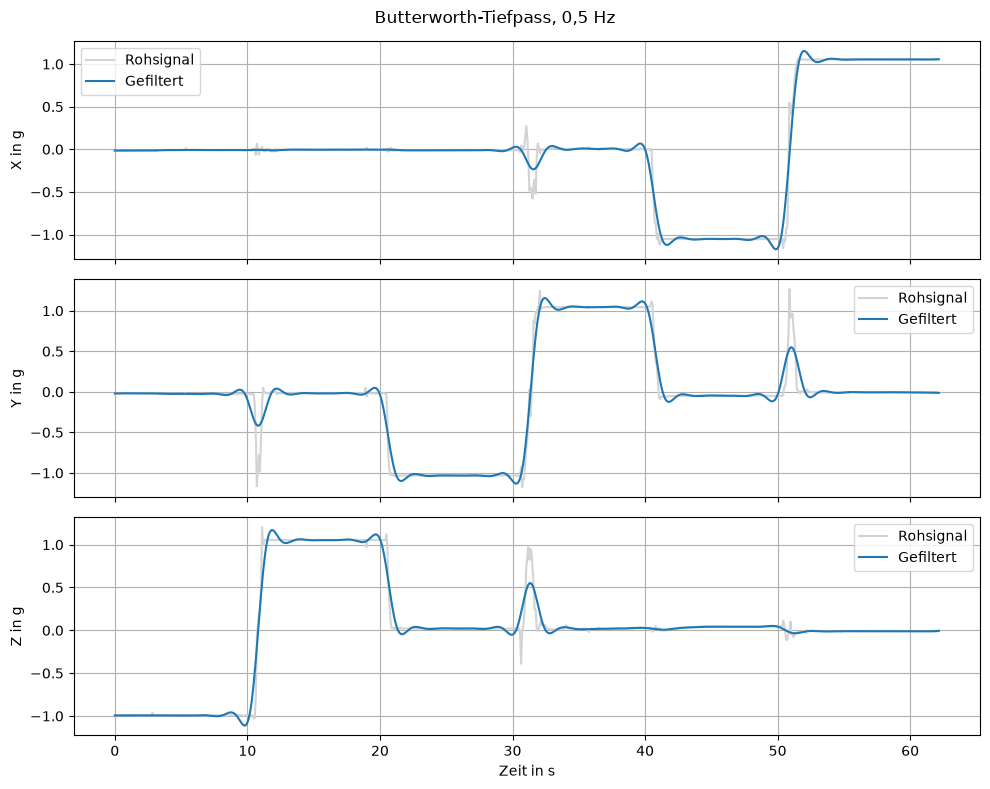

In [69]:
fig, axes_plot = plt.subplots(
    3,
    1,
    figsize=(10, 8),
    sharex=True
)

for axis_plot, axis_name in zip(axes_plot, ["X", "Y", "Z"]):
    axis_plot.plot(
        df["Time"],
        df[axis_name],
        color="lightgray",
        label="Rohsignal"
    )

    axis_plot.plot(
        df["Time"],
        df[f"{axis_name}_filtered"],
        label="Gefiltert"
    )

    axis_plot.set_ylabel(f"{axis_name} in g")
    axis_plot.grid()
    axis_plot.legend()

axes_plot[-1].set_xlabel("Zeit in s")
fig.suptitle("Butterworth-Tiefpass, 0,5 Hz")
plt.tight_layout()
plt.show()